# What is in the insertions

Every SV insertion in the panel (> 50 bp, **172,220 records**) annotated for transposable element
content with RepeatMasker, using GraffiTE's masking protocol.

## How this was produced, step by step

**1. Where the insertions come from.** The 82 chromosome-level assemblies were aligned into a
minigraph-cactus pangenome; bubbles were decomposed into biallelic records, and an *insertion* is a
record whose ALT allele carries sequence present in a founder and **absent from TAIR10/Col-0** at that
locus. Median 754 bp, 57.5% private to a single founder.

**No frequency or call-rate filter is applied anywhere in this notebook.** That is a choice about *this*
notebook, not a general position: the aim here is to describe the TE landscape of the insertions as it
is, so every segregating insertion is included, singletons and poorly-called sites alike. The modelling
that uses cargo downstream will apply the project's usual filters — MAC and the 0.9 founder call rate —
because an estimate needs variants that were measured reliably in every founder. The numbers here are
therefore a description of the landscape, and are not directly comparable to the filtered sets used in
the burden model (18,418 events, of which 12,981 insertions).

**2. The sequence itself.** Because an insertion is absent from the reference, it has no reference
coordinates: TAIR10 can say *where it landed* but never *what it contains*. The inserted sequence is
therefore extracted directly from the VCF ALT alleles, one FASTA per chromosome
(`results/sv_adaptive/seq/insertions_Chr*.fa`).

**3. The library.** RepeatMasker compares sequence against a library of TE consensus sequences, so the
library is the single most consequential choice here. Three were considered:

| source | A. thaliana families | verdict |
|---|---|---|
| **Dfam** (ships with RepeatMasker) | **0** | unusable — its entire curated Viridiplantae holding is 300 families, 242 of them castor bean, the rest green algae |
| **TAIR10** `transposable_element` records | 320 | usable, but Col-0-only |
| **RepBase 31.09**, `athrep.ref` | **1,136** | the curated source for this species |

The library was measured rather than assumed. Masking the burden model's 12,981 insertions with each:

```
TAIR10 only   60.95%  of inserted bases masked
RepBase only  75.66%
combined      76.83%
```

RepBase adds **15 points** over TAIR10; TAIR10 adds **1 point** over RepBase. This notebook uses the
combined library (1,456 sequences), but RepBase is doing nearly all the work. That gap matters
biologically, not just technically: a Col-0-derived library cannot see families absent from Col-0, which
is exactly where an excess of insertions in one group of founders could hide.

RepBase headers (`>name<TAB>class<TAB>species`) were converted to RepeatMasker's
`>name#Class/Superfamily` convention; three entries carrying a family name in the class field were passed
through as `Unknown` rather than guessed at.

*(The three-library comparison was made with the earlier masking settings, `-nolow -norna` at default
speed; it decided the library, and the library is unchanged.)*

**4. Masking — GraffiTE's protocol, on every record.** RepeatMasker 4.2 in slow mode (`-s`) with
**low-complexity masking on**, exactly as GraffiTE runs it, inside the GraffiTE container. GraffiTE masked
155,986 of the panel's SV records itself; the 71,865 it skips (replacement records that bcftools does not
type as indels — see below) were masked with the same steps, verified row-identical to GraffiTE on 300
of its own sequences. The full route is in `r1_sv_negative_selection/TE_CLASSIFICATION_PIPELINE.md`.

This replaces an earlier run with `-nolow`, which GraffiTE's authors warn against: with low-complexity
masking off, TE consensus sequences claim microsatellites. In that run 2,390 short insertions (median
120 bp) that are entirely simple repeat or satellite were called whole TEs.

**5. From hits to a per-insertion call.** For each insertion, from the raw RepeatMasker hits:

- coverage is the **union** of hit intervals, so an LTR element reported as separate 5′ LTR, internal
  and 3′ LTR hits is counted **once**, and overlapping hits are not double counted;
- only **TE classes** count towards the TE fraction; `Simple_repeat`, `Low_complexity` and `Satellite` are
  measured separately (`span_simple`);
- **family** is the TE family covering the most of that insertion;
- the result is a **fraction of the insertion covered by TE**, not a label.

GraffiTE's own span, which comes from OneCodeToFindThemAll, is not used: OneCode emits no Helitron
copies at all, so it is blind to the commonest superfamily in this panel.

**Replacement records.** 29% of insertion records are not a pure gain of sequence: the HPRC decomposition
calls them `COMPLEX` (the ALT path replaces reference nodes), or they swap one reference base. For these the
classified sequence is the whole ALT, including what replaces reference. They are flagged (`repl`), and §2
shows them separately.

Keeping a fraction rather than a yes/no is the point of doing it this way. It separates an insertion that
essentially *is* a mobile element from one that merely carries a piece of one, and it makes the inevitable
loss of power on short sequences visible as a gradient instead of hiding it inside a category.

**6. The classes**, cut on that fraction:

`te_full` ≥ 0.80 · `te_most` ≥ 0.50 · `te_partial` ≥ 0.20 · `te_trace` > 0 · `non_te` = 0

The 0.80 cut is the threshold GraffiTE uses to call a polymorphic mobile element.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:
import os
# the GraffiTE-protocol classification of every SV record (TE_CLASSIFICATION_PIPELINE.md); insertions
# > 50 bp, the same 172,220 as insertion_context.csv (the 790 of exactly 50 bp have no site context)
R=pd.read_csv(f"{G}/graffite/sv_repeat_class_records.csv")
N=R[(R.kind=="ins")&(R.size_bp>50)].rename(columns={"span_te":"te_frac","top_family":"family",
                                                    "top_superfamily":"cls","top_div":"div"}).copy()
N["size"]=N.size_bp           # net inserted bases (bins, medians); the TE fraction is over seq_len, the classified ALT
N["repl"]=(N.hprc_type=="COMPLEX")|(N.unshared_bp>0)
C=pd.read_csv(f"{G}/insertion_context.csv",low_memory=False); C["key"]=C.chrom+"|"+C.rec.astype(str)
assert set(N.key)==set(C.key), "insertion universe differs from insertion_context.csv"
M=N.merge(C[["key","genic","te_overlap","freq","n_alt","carrier_bio1"]],on="key",how="left")
ORD=["te_full","te_most","te_partial","te_trace","non_te"]
CCg={"te_full":"#B04A00","te_most":"#D48241","te_partial":"#E8BE97","te_trace":"#CFCFCF","non_te":"#8C8C8C"}
M["cargo"]=pd.Categorical(M.cargo,ORD,ordered=True)
print(f"{len(M):,} insertions: {M['size'].sum()/1e6:.1f} Mb net inserted, {M.seq_len.sum()/1e6:.1f} Mb of ALT sequence classified")
print(f"masked as TE: {M.te_bp.sum()/1e6:.1f} Mb = {100*M.te_bp.sum()/M.seq_len.sum():.1f}% of the classified sequence")
print(f"insertions with at least one TE hit: {int((M.te_bp>0).sum()):,}")
print(f"masked as simple repeat / low complexity / satellite: "
      f"{(M.span_simple*M.seq_len).sum()/1e6:.1f} Mb (kept out of the TE fraction)")
print(f"replacement records (COMPLEX, or a swapped base): {int(M.repl.sum()):,} "
      f"({100*M.repl.mean():.1f}%) -- masked by the GraffiTE-step rerun: "
      f"{int((M.annotated_by=='graffite_steps_rerun').sum()):,}")
# the burden model's site cascade, for the insertions that carry one. `insertion_context.csv` uses an
# OLDER and DIFFERENT scheme (CDS / UTR / intron / exon_noncoding / intergenic, plus a separate
# te_overlap flag) that has no TE or promoter category, so its "intergenic" pools what the burden model
# splits into TE, promoter and intergenic. The two are not interchangeable and are kept separate here.
CAT=pd.read_csv(f"{G}/sv_event_catalog.csv")
M=M.merge(CAT.loc[CAT.kind=="ins",["key","context","passes"]],on="key",how="left")
print(f"with the burden model's cascade context: {int(M.context.notna().sum()):,}")


172,220 insertions: 388.6 Mb net inserted, 457.5 Mb of ALT sequence classified
masked as TE: 287.0 Mb = 62.7% of the classified sequence
insertions with at least one TE hit: 122,057
masked as simple repeat / low complexity / satellite: 6.4 Mb (kept out of the TE fraction)
replacement records (COMPLEX, or a swapped base): 49,751 (28.9%) -- masked by the GraffiTE-step rerun: 49,704


with the burden model's cascade context: 50,231


## 1 · The cargo spectrum, two ways

The same data counted by **insertions** and by **base pairs**. They give different pictures because the
classes differ about four-fold in median size, and which one to quote depends on the question: the burden model counts
*events*, so the left panel is the one that matters there; the right panel is the one to quote for "how
much of the inserted DNA in this species is transposon".

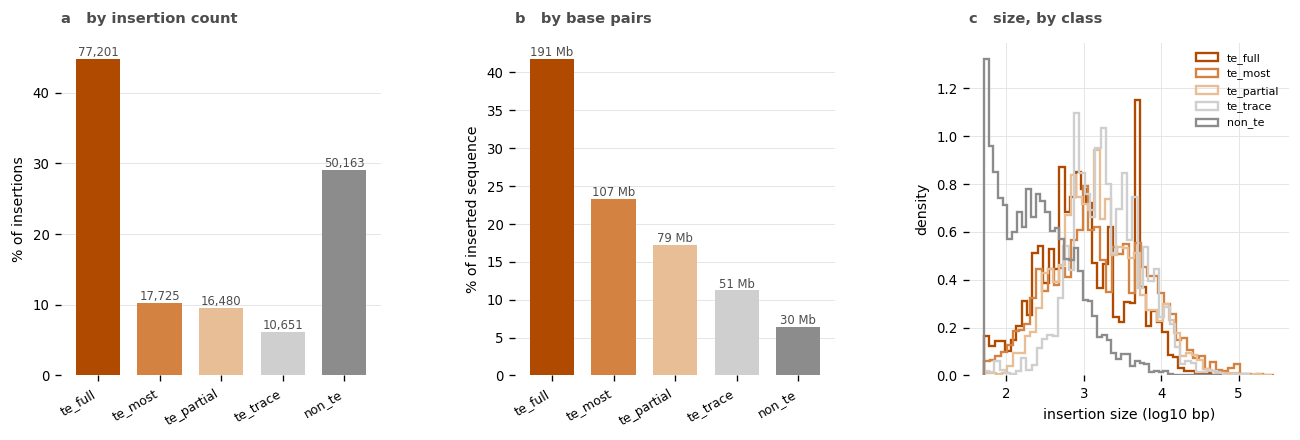

THE SAME DATA, TWO DENOMINATORS

  class         insertions  % of count  median bp       Mb  % of sequence
  te_full           77,201       44.8%        924    191.3          41.8%
  te_most           17,725       10.3%       1459    106.6          23.3%
  te_partial        16,480        9.6%       1459     78.8          17.2%
  te_trace          10,651        6.2%       1830     51.3          11.2%
  non_te            50,163       29.1%        226     29.5           6.5%

  non_te is 29% of insertions but only 6% of sequence
  because its median insertion is 226 bp against 924 bp for te_full (4x)


In [3]:

g=M.groupby("cargo").agg(n=("key","size"),bp=("seq_len","sum"),te=("te_bp","sum"),
                         med=("size","median")).reindex(ORD)
fig,axs=plt.subplots(1,3,figsize=(13.2,3.6),gridspec_kw=dict(wspace=0.42))
a=axs[0]; style(a,axis="y")
a.bar(range(len(ORD)),100*g.n/g.n.sum(),color=[CCg[c] for c in ORD],width=0.72)
for i,c in enumerate(ORD):
    a.annotate(f"{g.n[c]:,}",xy=(i,100*g.n[c]/g.n.sum()),ha="center",va="bottom",fontsize=7,color="0.3")
a.set_xticks(range(len(ORD))); a.set_xticklabels(ORD,fontsize=7.5,rotation=30,ha="right")
a.set_ylabel("% of insertions",fontsize=8.5)
a.annotate("a   by insertion count",xy=(0,1.06),xycoords="axes fraction",fontsize=8.8,
           fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="y")
a.bar(range(len(ORD)),100*g.bp/g.bp.sum(),color=[CCg[c] for c in ORD],width=0.72)
for i,c in enumerate(ORD):
    a.annotate(f"{g.bp[c]/1e6:.0f} Mb",xy=(i,100*g.bp[c]/g.bp.sum()),ha="center",va="bottom",
               fontsize=7,color="0.3")
a.set_xticks(range(len(ORD))); a.set_xticklabels(ORD,fontsize=7.5,rotation=30,ha="right")
a.set_ylabel("% of inserted sequence",fontsize=8.5)
a.annotate("b   by base pairs",xy=(0,1.06),xycoords="axes fraction",fontsize=8.8,
           fontweight="bold",color="0.3")
a=axs[2]; style(a,axis="both")
for c in ORD:
    v=M.loc[M.cargo==c,"size"]
    a.hist(np.log10(v[v>0]),bins=50,histtype="step",lw=1.4,color=CCg[c],label=c,density=True)
a.set_xlabel("insertion size (log10 bp)",fontsize=8.5); a.set_ylabel("density",fontsize=8.5)
a.legend(fontsize=6.6,frameon=False)
a.annotate("c   size, by class",xy=(0,1.06),xycoords="axes fraction",fontsize=8.8,
           fontweight="bold",color="0.3")
save(fig,"cargorm_spectrum",nb=True); plt.show()
t=g.assign(pct_n=100*g.n/g.n.sum(),pct_bp=100*g.bp/g.bp.sum(),
           pct_masked=100*g.te/g.bp)
print("THE SAME DATA, TWO DENOMINATORS\n")
print(f"  {'class':12s} {'insertions':>11s} {'% of count':>11s} {'median bp':>10s} "
      f"{'Mb':>8s} {'% of sequence':>14s}")
for c in ORD:
    print(f"  {c:12s} {g.n[c]:11,d} {t.pct_n[c]:10.1f}% {g.med[c]:10.0f} {g.bp[c]/1e6:8.1f} "
          f"{t.pct_bp[c]:13.1f}%")
nt,tf=g.loc["non_te"],g.loc["te_full"]
print(f"\n  non_te is {100*nt.n/g.n.sum():.0f}% of insertions but only {100*nt.bp/g.bp.sum():.0f}% of sequence")
print(f"  because its median insertion is {nt.med:.0f} bp against {tf.med:.0f} bp for te_full "
      f"({tf.med/nt.med:.0f}x)")


## 2 · TE content against insertion length

Short sequences carry less of an element and also give an alignment search less to work with, so TE
content and length are related for both a biological and a methodological reason, and the two cannot be
fully separated. Keeping a graded measure means this appears as a curve that can be read directly, and
any analysis using cargo can stratify on size rather than assume the issue away.

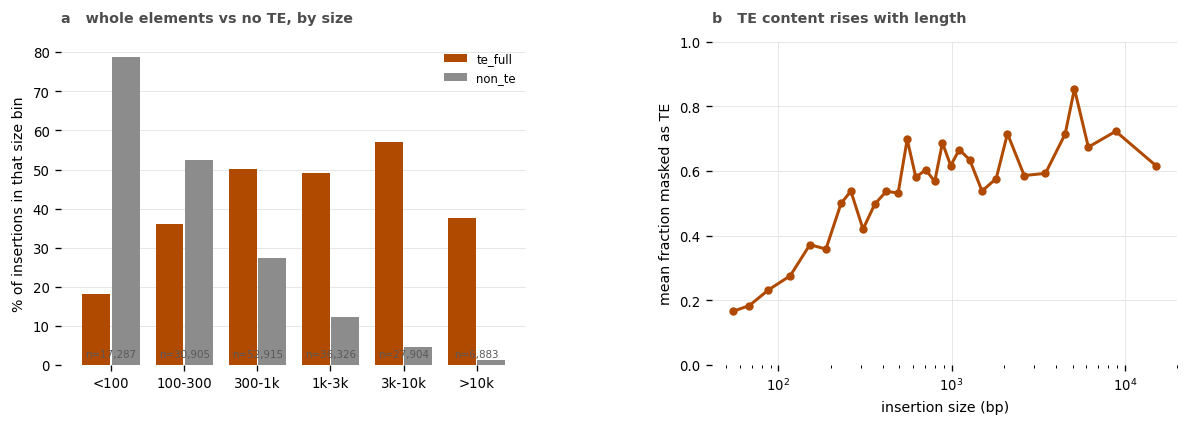

TE CONTENT BY INSERTION SIZE

             n  mean_frac  pct_full  pct_non
szbin                                       
<100     17287        0.2      18.2     78.7
100-300  30905        0.4      36.1     52.4
300-1k   52915        0.6      50.2     27.3
1k-3k    36326        0.6      49.1     12.4
3k-10k   27904        0.7      57.1      4.7
>10k      6883        0.6      37.5      1.4

% te_full, CLEAN records vs REPLACEMENT records (the class of a replacement describes the whole ALT,
including the sequence that replaces reference)

         n clean  n replacement  % full clean  % full replacement
szbin                                                            
<100       14128           3159          18.3                18.1
100-300    24053           6852          36.3                35.2
300-1k     42002          10913          53.3                38.3
1k-3k      23103          13223          56.7                35.8
3k-10k     16543          11361          67.1                42

In [4]:

M["szbin"]=pd.cut(M["size"],[0,100,300,1000,3000,10000,10**9],
                  labels=["<100","100-300","300-1k","1k-3k","3k-10k",">10k"])
t=M.groupby("szbin").agg(n=("key","size"),mean_frac=("te_frac","mean"),
                         pct_full=("cargo",lambda s:100*(s=="te_full").mean()),
                         pct_non=("cargo",lambda s:100*(s=="non_te").mean()))
fig,axs=plt.subplots(1,2,figsize=(12.0,3.5),gridspec_kw=dict(wspace=0.40))
a=axs[0]; style(a,axis="y")
x=np.arange(len(t))
a.bar(x,t.pct_full,color=CCg["te_full"],width=0.38,label="te_full")
a.bar(x+0.40,t.pct_non,color=CCg["non_te"],width=0.38,label="non_te")
a.set_xticks(x+0.20); a.set_xticklabels(t.index,fontsize=8)
a.set_ylabel("% of insertions in that size bin",fontsize=8.5)
a.legend(fontsize=7,frameon=False)
for i,n in enumerate(t.n): a.annotate(f"n={n:,}",xy=(i+0.2,2),ha="center",fontsize=6.2,color="0.35")
a.annotate("a   whole elements vs no TE, by size",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.6,fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="both")
b=M[M["size"]>0].copy(); b["lg"]=np.log10(b["size"])
q=pd.qcut(b.lg,30,duplicates="drop")
m=b.groupby(q).agg(x=("lg","median"),y=("te_frac","mean"),n=("key","size"))
a.plot(10**m.x,m.y,color="#B04A00",lw=1.8)
a.scatter(10**m.x,m.y,s=16,color="#B04A00",zorder=3)
a.set_xscale("log"); a.set_xlabel("insertion size (bp)",fontsize=8.5)
a.set_ylabel("mean fraction masked as TE",fontsize=8.5); a.set_ylim(0,1)
a.annotate("b   TE content rises with length",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.6,fontweight="bold",color="0.3")
save(fig,"cargorm_size",nb=True); plt.show()
print("TE CONTENT BY INSERTION SIZE\n")
print(t.round(1).to_string())
print("\n% te_full, CLEAN records vs REPLACEMENT records (the class of a replacement describes the whole ALT,")
print("including the sequence that replaces reference)\n")
print(M.assign(full=M.cargo=="te_full").pivot_table(index="szbin",columns="repl",values="full",
      aggfunc=["size","mean"],observed=True).pipe(lambda d: d.set_axis(
      ["n clean","n replacement","% full clean","% full replacement"],axis=1))
      .assign(**{"% full clean":lambda d:(100*d["% full clean"]).round(1),
                 "% full replacement":lambda d:(100*d["% full replacement"]).round(1)}).to_string())


## 3 · Which families, and where they land

Family is the library entry covering the most of that insertion, so an insertion made of one element gets
that element's family.

⚠ **Two different site classifications exist in this project, and they are not interchangeable.**

| | categories | source |
|---|---|---|
| `genic` (panel b) | CDS · UTR · intron · exon_noncoding · intergenic, plus a separate TE-overlap flag | `_insertion_genomic_context.py`, all 172,220 insertions |
| **cascade** (panel c) | CDS > UTR > intron > **TE** > **promoter ≤1 kb** > intergenic, first match wins | `_sv_sfs_context.py`, **this is what the burden model fits** |

The older scheme has **no TE and no promoter category**, so its `intergenic` pools all three: of its 131,685
intergenic insertions, the cascade calls 12,961 intergenic, 11,679 promoter and 10,705 TE. Panel c is
therefore the one to compare against anything in `sv_burden_model.ipynb`; it covers the insertions present
in the event catalogue.

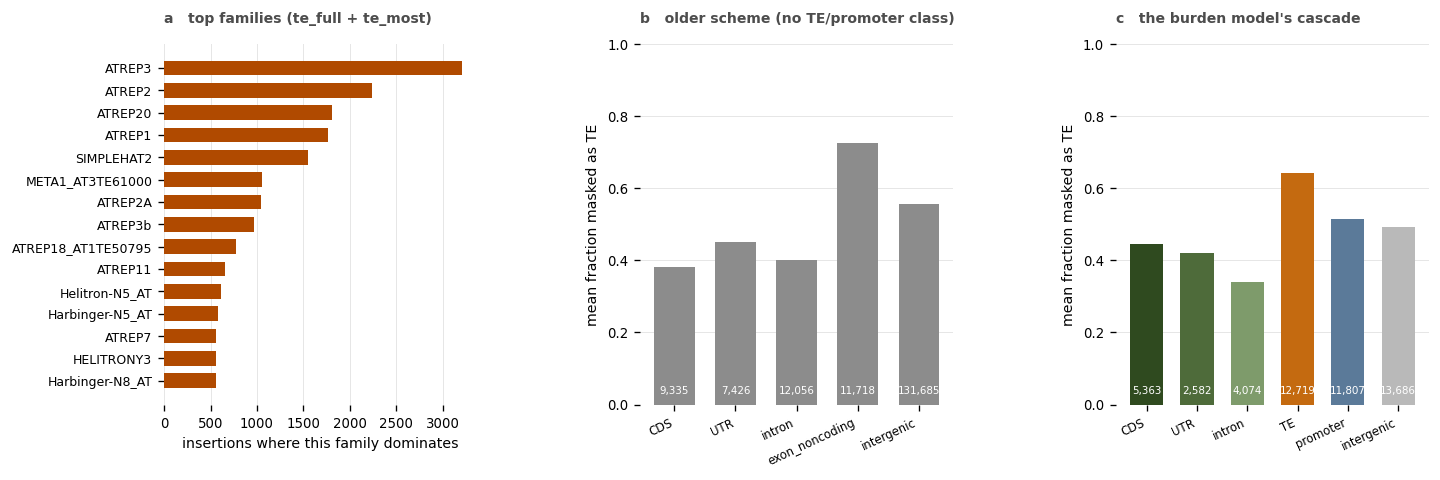

TOP FAMILIES

family
ATREP3                3210
ATREP2                2236
ATREP20               1805
ATREP1                1759
SIMPLEHAT2            1549
META1_AT3TE61000      1048
ATREP2A               1045
ATREP3b                966
ATREP18_AT1TE50795     775
ATREP11                653
Helitron-N5_AT         617
Harbinger-N5_AT        583
ATREP7                 555
HELITRONY3             555
Harbinger-N8_AT        554

TE CONTENT BY LANDING SITE -- the burden model's cascade

                n  mean_te  pct_full
context                             
CDS          5363    0.445    29.554
UTR          2582    0.420    33.888
intron       4074    0.341    29.921
TE          12719    0.643    55.688
promoter    11807    0.516    43.847
intergenic  13686    0.493    42.459

HOW THE TWO SCHEMES MAP ONTO EACH OTHER (rows = older scheme)

context          CDS     TE   UTR  intergenic  intron  promoter
genic                                                          
CDS             3509      0

In [5]:
te=M[M.cargo.isin(["te_full","te_most"])]
top=te.family.value_counts().head(15)
fig,axs=plt.subplots(1,3,figsize=(13.6,3.9),gridspec_kw=dict(wspace=0.52))
a=axs[0]; style(a,axis="x")
yy=np.arange(len(top))[::-1]
a.barh(yy,top.to_numpy(),color="#B04A00",height=0.66)
a.set_yticks(yy); a.set_yticklabels(top.index,fontsize=7.5)
a.set_xlabel("insertions where this family dominates",fontsize=8.5)
a.annotate("a   top families (te_full + te_most)",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="y")
ctx=[c for c in ["CDS","UTR","intron","exon_noncoding","intergenic"] if c in set(M.genic)]
sm=M.groupby("genic").te_frac.mean().reindex(ctx)
a.bar(range(len(ctx)),sm,color="#8C8C8C",width=0.66)
a.set_xticks(range(len(ctx))); a.set_xticklabels(ctx,fontsize=7,rotation=25,ha="right")
a.set_ylabel("mean fraction masked as TE",fontsize=8.5); a.set_ylim(0,1)
for i,c in enumerate(ctx):
    a.annotate(f"{int((M.genic==c).sum()):,}",xy=(i,0.03),ha="center",fontsize=6.2,color="white")
a.annotate("b   older scheme (no TE/promoter class)",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
a=axs[2]; style(a,axis="y")
CX=["CDS","UTR","intron","TE","promoter","intergenic"]
CXC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10",
     "promoter":"#5B7A99","intergenic":"#B9B9B9"}
sc=M[M.context.notna()].groupby("context").te_frac.mean().reindex(CX)
a.bar(range(len(CX)),sc,color=[CXC[c] for c in CX],width=0.66)
a.set_xticks(range(len(CX))); a.set_xticklabels(CX,fontsize=7,rotation=25,ha="right")
a.set_ylabel("mean fraction masked as TE",fontsize=8.5); a.set_ylim(0,1)
for i,c in enumerate(CX):
    a.annotate(f"{int((M.context==c).sum()):,}",xy=(i,0.03),ha="center",fontsize=6.2,color="white")
a.annotate("c   the burden model's cascade",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
save(fig,"cargorm_families",nb=True); plt.show()
print("TOP FAMILIES\n"); print(top.to_string())
print("\nTE CONTENT BY LANDING SITE -- the burden model's cascade\n")
print(M[M.context.notna()].groupby("context").agg(n=("key","size"),mean_te=("te_frac","mean"),
      pct_full=("cargo",lambda s:100*(s=="te_full").mean())).reindex(CX).round(3).to_string())
print("\nHOW THE TWO SCHEMES MAP ONTO EACH OTHER (rows = older scheme)\n")
print(pd.crosstab(M.genic,M.context).to_string())
print("\n  The older scheme's `intergenic` is the cascade's TE + promoter + intergenic, which is why")
print("  panel b has no TE bar and panel c does. Nothing in the burden model uses the older scheme.")


## 4 · Is TE cargo related to where the carriers come from?

For each insertion, the **mean origin bio1 of the founders carrying it** — carrier sets and founder
origins only, no experimental data. The question is whether insertions carried by cold-origin founders
differ in TE content from those carried by warm-origin founders.

> **The trap this has to handle.** `carrier_bio1` is mathematically coupled to allele frequency: a
> singleton's value is one founder's origin exactly — an extreme — while a common insertion averages many
> carriers and regresses to the panel mean. A naive cold/warm split therefore pulls singletons into both
> tails, and any comparison between the groups is confounded **by construction**. The split is made
> **within carrier-count strata**, so the comparison is like-for-like, and consistency across strata is
> the evidence rather than the size of any single contrast.

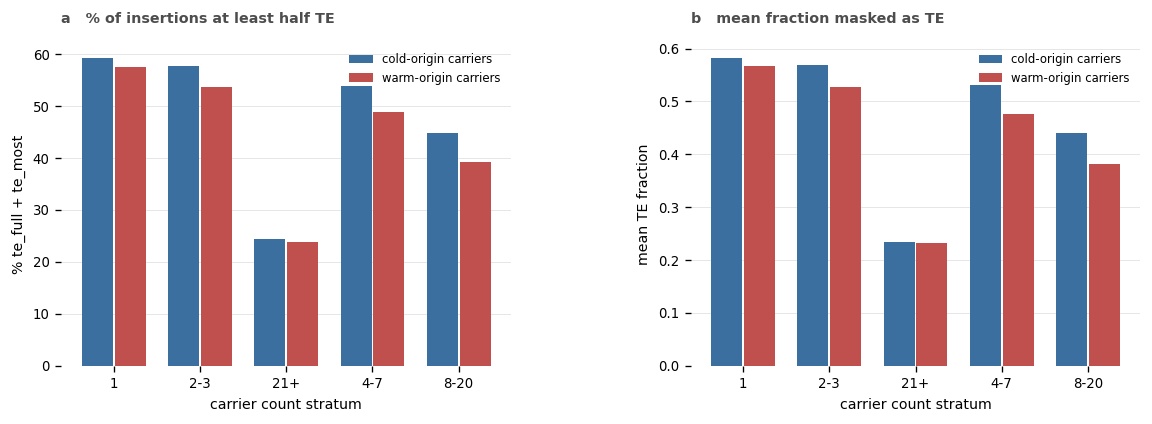

FREQUENCY-MATCHED COLD vs WARM CARRIERS  (median carrier_bio1 splits the two)

  stratum      n cold   n warm  % >=half TE cold     warm  mean frac cold     warm
  1            44,051   54,924              59.3     57.6           0.583    0.566
  2-3          20,952   17,459              57.7     53.7           0.569    0.528
  21+           3,248    1,644              24.3     23.8           0.234    0.233
  4-7          11,383    8,048              53.8     48.7           0.531    0.477
  8-20          6,464    4,047              44.8     39.2           0.439    0.381

  cold > warm in 5/5 strata on the class measure, 5/5 on the graded measure
  Consistency across strata is the evidence; a single stratum proves nothing, because the
  cold/warm split is only meaningful within one.


In [6]:

B=M[M.carrier_bio1.notna()].copy()
B["stratum"]=pd.cut(B.n_alt,[0,1,3,7,20,10**9],labels=["1","2-3","4-7","8-20","21+"])
med=B.carrier_bio1.median()
B["grp"]=np.where(B.carrier_bio1<med,"cold","warm")
rows=[]
for s,g in B.groupby("stratum"):
    for grp in ("cold","warm"):
        h=g[g.grp==grp]
        rows.append(dict(stratum=s,grp=grp,n=len(h),
                         pct_te=100*h.cargo.isin(["te_full","te_most"]).mean(),
                         mean_frac=h.te_frac.mean()))
T=pd.DataFrame(rows)
P=T.pivot(index="stratum",columns="grp",values="pct_te")
Pf=T.pivot(index="stratum",columns="grp",values="mean_frac")
fig,axs=plt.subplots(1,2,figsize=(11.6,3.5),gridspec_kw=dict(wspace=0.40))
for a,D,lab,yl in ((axs[0],P,"a   % of insertions at least half TE","% te_full + te_most"),
                   (axs[1],Pf,"b   mean fraction masked as TE","mean TE fraction")):
    style(a,axis="y"); x=np.arange(len(D))
    a.bar(x-0.19,D["cold"],width=0.36,color="#3B6FA0",label="cold-origin carriers")
    a.bar(x+0.19,D["warm"],width=0.36,color="#C0504D",label="warm-origin carriers")
    a.set_xticks(x); a.set_xticklabels(D.index,fontsize=8)
    a.set_xlabel("carrier count stratum",fontsize=8.5); a.set_ylabel(yl,fontsize=8.5)
    a.legend(fontsize=7,frameon=False)
    a.annotate(lab,xy=(0,1.06),xycoords="axes fraction",fontsize=8.6,fontweight="bold",color="0.3")
save(fig,"cargorm_cold",nb=True); plt.show()
print("FREQUENCY-MATCHED COLD vs WARM CARRIERS  (median carrier_bio1 splits the two)\n")
print(f"  {'stratum':10s} {'n cold':>8s} {'n warm':>8s} {'% >=half TE cold':>17s} {'warm':>8s} "
      f"{'mean frac cold':>15s} {'warm':>8s}")
for s in P.index:
    nc=int(T[(T.stratum==s)&(T.grp=='cold')].n.iloc[0]); nw=int(T[(T.stratum==s)&(T.grp=='warm')].n.iloc[0])
    print(f"  {str(s):10s} {nc:8,d} {nw:8,d} {P.loc[s,'cold']:17.1f} {P.loc[s,'warm']:8.1f} "
          f"{Pf.loc[s,'cold']:15.3f} {Pf.loc[s,'warm']:8.3f}")
k=int((P["cold"]>P["warm"]).sum())
print(f"\n  cold > warm in {k}/{len(P)} strata on the class measure, "
      f"{int((Pf['cold']>Pf['warm']).sum())}/{len(Pf)} on the graded measure")
print("  Consistency across strata is the evidence; a single stratum proves nothing, because the")
print("  cold/warm split is only meaningful within one.")


## 5 · Does the TE composition shift along the carriers' climate?

Not "cold versus warm" as a split, but the whole temperature range as a gradient: among insertions
carried by founders from progressively warmer homes, does the **mix of element families** change?

**The cleanest window is the singletons.** For an insertion carried by exactly one founder,
`carrier_bio1` **is** that founder's home temperature — no averaging, no regression toward the panel
mean, and none of the frequency coupling that makes a cold/warm split on common insertions
uninterpretable. 98,975 insertions qualify, 57% of the panel.

Panel **a** is that: the composition of TE classes across the temperature range, as a stacked area.
Panel **b** repeats it on insertions with 2-20 carriers, where `carrier_bio1` is an average and therefore
compressed toward the middle — if a gradient is real it should still be visible, just shallower.
Panel **c** picks out the individual classes as lines, which is where a family-specific shift would show.

⚠ A composition plot has no spare degrees of freedom: the shares must sum to 100% in every bin, so one
class rising forces the others down. Read the lines in panel c, not the band thicknesses in a and b.

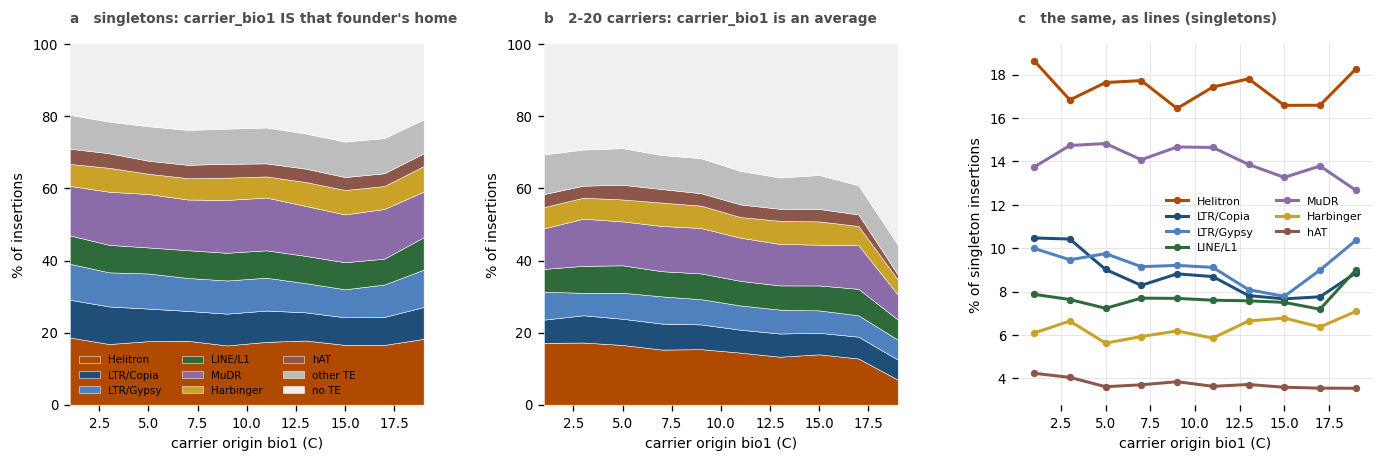

SINGLETON INSERTIONS: TE CLASS COMPOSITION ACROSS CARRIER HOME TEMPERATURE (%)

tgrp          Helitron  LTR/Copia  LTR/Gypsy  LINE/L1  MuDR  Harbinger  hAT  other TE  no TE
tbin                                                                                        
(0.0, 2.0]        18.6       10.5       10.0      7.9  13.7        6.1  4.2       9.4   19.6
(2.0, 4.0]        16.8       10.4        9.5      7.6  14.7        6.6  4.0       8.8   21.5
(4.0, 6.0]        17.6        9.0        9.7      7.2  14.8        5.6  3.6       9.6   22.7
(6.0, 8.0]        17.7        8.3        9.1      7.7  14.1        5.9  3.7       9.7   23.8
(8.0, 10.0]       16.4        8.8        9.2      7.7  14.7        6.2  3.8       9.8   23.4
(10.0, 12.0]      17.4        8.7        9.1      7.6  14.6        5.9  3.6      10.0   23.1
(12.0, 14.0]      17.8        7.8        8.1      7.6  13.9        6.6  3.7       9.7   24.8
(14.0, 16.0]      16.6        7.7        7.8      7.5  13.3        6.8  3.6       9

In [7]:
GRP={"RC/Helitron":"Helitron","LTR/Copia":"LTR/Copia","LTR/Gypsy":"LTR/Gypsy","LINE/L1":"LINE/L1",
     "DNA/MULE-MuDR":"MuDR","DNA/MuDR":"MuDR","DNA/PIF-Harbinger":"Harbinger","DNA/hAT":"hAT"}
CLC={"Helitron":"#B04A00","LTR/Copia":"#1F4E79","LTR/Gypsy":"#4E81BD","LINE/L1":"#2F6B3A",
     "MuDR":"#8B6BA8","Harbinger":"#C9A227","hAT":"#8C564B","other TE":"#BDBDBD","no TE":"#F0F0F0"}
def grp(r):
    if r.te_frac<=0: return "no TE"
    return GRP.get(r.cls,"other TE")
M["tgrp"]=[grp(r) for r in M.itertuples()]
ORDC=["Helitron","LTR/Copia","LTR/Gypsy","LINE/L1","MuDR","Harbinger","hAT","other TE","no TE"]
B=M[M.carrier_bio1.notna()].copy()
EDG=np.arange(0,21,2.0)
B["tbin"]=pd.cut(B.carrier_bio1,EDG)
PAN=[("a   singletons: carrier_bio1 IS that founder's home",B[B.n_alt==1]),
     ("b   2-20 carriers: carrier_bio1 is an average",B[(B.n_alt>=2)&(B.n_alt<=20)])]
fig,axs=plt.subplots(1,3,figsize=(14.0,3.9),gridspec_kw=dict(wspace=0.34))
for a,(lab,D) in zip(axs,PAN):
    style(a,axis="both")
    ct=pd.crosstab(D.tbin,D.tgrp,normalize="index")*100
    ct=ct.reindex(columns=[c for c in ORDC if c in ct.columns]).fillna(0)
    x=[iv.mid for iv in ct.index]
    a.stackplot(x,[ct[c] for c in ct.columns],labels=list(ct.columns),
                colors=[CLC[c] for c in ct.columns],edgecolor="white",linewidth=0.3)
    a.set_xlabel("carrier origin bio1 (C)",fontsize=8.5); a.set_ylabel("% of insertions",fontsize=8.5)
    a.set_ylim(0,100); a.set_xlim(min(x),max(x))
    a.annotate(lab,xy=(0,1.06),xycoords="axes fraction",fontsize=8.2,fontweight="bold",color="0.3")
a=axs[2]; style(a,axis="both")
D=B[B.n_alt==1]
ct=pd.crosstab(D.tbin,D.tgrp,normalize="index")*100
x=[iv.mid for iv in ct.index]
for c in [c for c in ORDC if c in ct.columns and c not in ("no TE","other TE")]:
    a.plot(x,ct[c],color=CLC[c],lw=1.8,marker="o",ms=3.4,label=c)
a.set_xlabel("carrier origin bio1 (C)",fontsize=8.5)
a.set_ylabel("% of singleton insertions",fontsize=8.5)
a.legend(fontsize=6.6,frameon=False,ncol=2)
a.annotate("c   the same, as lines (singletons)",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.2,fontweight="bold",color="0.3")
axs[0].legend(fontsize=6.2,frameon=False,loc="lower left",ncol=3)
save(fig,"cargorm_climate_gradient",nb=True); plt.show()
print("SINGLETON INSERTIONS: TE CLASS COMPOSITION ACROSS CARRIER HOME TEMPERATURE (%)\n")
D=B[B.n_alt==1]; ct=pd.crosstab(D.tbin,D.tgrp,normalize="index")*100
ct=ct.reindex(columns=[c for c in ORDC if c in ct.columns])
print(ct.round(1).to_string())
print("\n  n per bin:"); print(D.tbin.value_counts().sort_index().to_string())
print("\nTREND ACROSS THE RANGE (coldest bin -> warmest bin, singletons)\n")
print(f"  {'class':12s} {'coldest':>9s} {'warmest':>9s} {'change':>9s}")
for c in ct.columns:
    v=ct[c].dropna()
    if len(v)>1: print(f"  {c:12s} {v.iloc[0]:9.1f} {v.iloc[-1]:9.1f} {v.iloc[-1]-v.iloc[0]:+9.1f}")
print("\n  Shares are constrained to sum to 100 in every bin, so a rise in one class is partly the")
print("  mirror of a fall in another. The per-class lines in panel c are the readable version.")


## 6 · ATCOPIA78 / ONSEN

One family stands out, and it is worth a section of its own because it is the only family-level signal in
the dataset and because it comes with a trap.

**ATCOPIA78 is ONSEN**, the heat-activated copia retrotransposon of *Arabidopsis*. Two things make it
unusual here: it is overwhelmingly present as **near-full-length, essentially undiverged** copies, and its
insertions are carried disproportionately by **cold**-origin founders — the opposite of what the name
suggests.

Three questions, in order of how much they could undo the result:

**(a) Is it real cargo, or a mis-call?** Size, TE fraction and divergence say what kind of sequence it is.

**(b) Is the cold enrichment an artefact of allele frequency?** `carrier_bio1` is coupled to carrier
count, so the comparison is made **within carrier-count strata**.

**(c) Is it one lineage, or the population?** Some 540 near-identical elements is exactly what a single recent
burst in one clade would look like, and a burst in a clade that happens to be cold-origin would produce
the same table. This is the question the earlier analysis could not answer, because it counted
*insertions* rather than *founders*. Panel c counts founders.

(a) WHAT KIND OF SEQUENCE IS IT

                            ATCOPIA78   all other TE
  n insertions                    541        121,516
  median size (bp)           4961.000       1097.000
  median TE fraction            0.998          0.947
  median divergence (%)         0.500          7.800

  Undiverged and full length: these are recent insertions, not ancient copies.


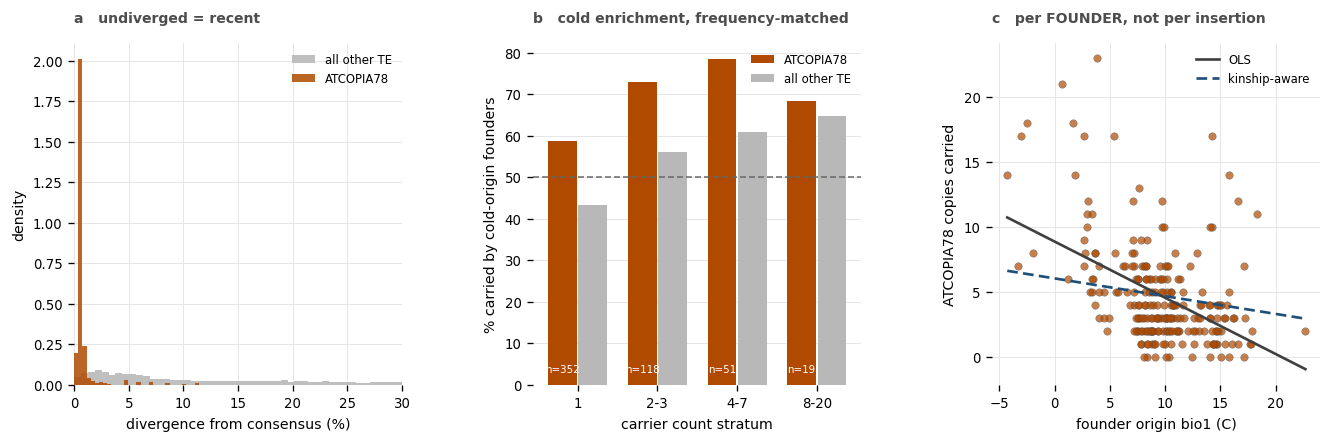


(b) COLD ENRICHMENT, FREQUENCY-MATCHED

  stratum      n   cold   warm  % cold (78)  % cold (rest)
  1          352    207    145        58.8%          43.4%
  2-3        118     86     32        72.9%          56.1%
  4-7         51     40     11        78.4%          60.9%
  8-20        19     13      6        68.4%          64.7%

  cold > warm in 4/4 strata
  pooled odds ratio 1.84, Fisher p = 5.19e-12  (pooled, so NOT frequency-matched -- the
  per-stratum consistency above is the evidence, not this number)

(c) ONE LINEAGE, OR THE POPULATION?

  founders carrying at least one: 221 of 231
  copies per founder: median 4, mean 4.7, max 23

  copies vs founder origin temperature:
    without kinship:  -0.4330 copies per degree C   r = -0.462, p = 1.24e-13
    with kinship:     -0.1367 +- 0.0536   z = -2.55, p = 0.0108
    kinship variance share: 1.000

  Not a single-lineage burst: almost every founder carries some, and the counts form a
  gradient rather than a presence/absence spl

In [8]:
import scipy.sparse as sp
from scipy import optimize
PANEL="/global/scratch/projects/fc_moilab/tbellg/kmate/panel/arch3"
A78=M[M.family.astype(str).str.contains("ATCOPIA78",na=False)].copy()
A78["chrom"]=A78.key.str.split("|").str[0]; A78["rec"]=A78.key.str.split("|").str[1].astype(int)
BG=M[(M.te_frac>0)&(~M.family.astype(str).str.contains("ATCOPIA78",na=False))]
print("(a) WHAT KIND OF SEQUENCE IS IT\n")
print(f"  {'':22s} {'ATCOPIA78':>12s} {'all other TE':>14s}")
for lab,col in (("n insertions","n"),("median size (bp)","size"),
                ("median TE fraction","te_frac"),("median divergence (%)","div")):
    if col=="n": print(f"  {lab:22s} {len(A78):12,d} {len(BG):14,d}")
    else: print(f"  {lab:22s} {A78[col].median():12.3f} {BG[col].median():14.3f}")
print("\n  Undiverged and full length: these are recent insertions, not ancient copies.")
B2=M[M.carrier_bio1.notna()&(M.te_frac>0)].copy()
B2["stratum"]=pd.cut(B2.n_alt,[0,1,3,7,20,10**9],labels=["1","2-3","4-7","8-20","21+"])
B2["is78"]=B2.family.astype(str).str.contains("ATCOPIA78",na=False)
mb=B2.carrier_bio1.median(); B2["grp"]=np.where(B2.carrier_bio1<mb,"cold","warm")
rows=[]
for s,g in B2.groupby("stratum"):
    g78=g[g.is78]
    if len(g78)<10: continue
    rows.append(dict(stratum=str(s),n=len(g78),cold=int((g78.grp=="cold").sum()),
                     warm=int((g78.grp=="warm").sum()),
                     pct78=100*(g78.grp=="cold").mean(),
                     pctrest=100*(g[~g.is78].grp=="cold").mean()))
S=pd.DataFrame(rows)
ct=np.array([[int(B2[B2.is78].grp.eq("cold").sum()),int(B2[B2.is78].grp.eq("warm").sum())],
             [int(B2[~B2.is78].grp.eq("cold").sum()),int(B2[~B2.is78].grp.eq("warm").sum())]])
orr,pf=stats.fisher_exact(ct)
fo=None; cnt=None
for ch in sorted(A78.chrom.unique()):
    cl=ch.lower()
    mt=np.load(f"{PANEL}/{cl}/var_pa_231_arch3_{cl}.meta.npz",allow_pickle=True)
    f=[str(x) for x in mt["founders"]]
    if fo is None: fo=f; cnt=np.zeros(len(f),int)
    Mx=sp.load_npz(f"{PANEL}/{cl}/var_pa_231_arch3_{cl}.var_pa.npz").tocsr()
    cnt+=np.asarray((Mx[:,A78.loc[A78.chrom==ch,"rec"].to_numpy()]>0).sum(axis=1)).ravel()
BB=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
KK=pd.read_csv(f"{G}/onestage_all/kinship.csv",index_col=0)
KK.index=KK.index.astype(str); KK.columns=KK.columns.astype(str)
D78=pd.DataFrame({"founder":fo,"n78":cnt}).merge(BB[["founder","bio1"]],on="founder").dropna()
D78=D78[D78.founder.isin(KK.index)]
y=D78.n78.to_numpy(float); Xd=np.column_stack([np.ones(len(D78)),D78.bio1.to_numpy(float)])
ev,U=np.linalg.eigh(KK.loc[D78.founder,D78.founder].to_numpy()); Uy=U.T@y; UX=U.T@Xd
def _nll(h):
    d=h*ev+(1-h); W=1/d
    Am=UX.T@(UX*W[:,None]); b=np.linalg.solve(Am,UX.T@(Uy*W))
    r=Uy-UX@b; s2=float(r@(r*W))/len(y)
    return 0.5*(np.sum(np.log(d))+len(y)*np.log(s2)),b,Am,s2
h2=optimize.minimize_scalar(lambda h:_nll(min(max(h,1e-6),1-1e-6))[0],bounds=(1e-6,1-1e-6),
                            method="bounded").x
_,bk,Am,s2=_nll(h2); sek=np.sqrt(np.diag(np.linalg.inv(Am))*s2); zk=bk[1]/sek[1]
sl,ic=np.polyfit(D78.bio1,y,1); ro,po=stats.pearsonr(D78.bio1,y)
fig,axs=plt.subplots(1,3,figsize=(13.4,3.7),gridspec_kw=dict(wspace=0.40))
a=axs[0]; style(a,axis="both")
a.hist(BG["div"].dropna(),bins=60,color="0.75",density=True,label="all other TE")
a.hist(A78["div"].dropna(),bins=30,color="#B04A00",alpha=0.85,density=True,label="ATCOPIA78")
a.set_xlabel("divergence from consensus (%)",fontsize=8.5); a.set_ylabel("density",fontsize=8.5)
a.set_xlim(0,30); a.legend(fontsize=7,frameon=False)
a.annotate("a   undiverged = recent",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="y")
x=np.arange(len(S))
a.bar(x-0.19,S.pct78,width=0.36,color="#B04A00",label="ATCOPIA78")
a.bar(x+0.19,S.pctrest,width=0.36,color="0.72",label="all other TE")
a.axhline(50,color="0.4",lw=0.9,ls=(0,(4,2)))
a.set_xticks(x); a.set_xticklabels(S.stratum,fontsize=8)
a.set_xlabel("carrier count stratum",fontsize=8.5)
a.set_ylabel("% carried by cold-origin founders",fontsize=8.5)
a.legend(fontsize=7,frameon=False)
for i,n in enumerate(S.n): a.annotate(f"n={n}",xy=(i-0.19,3),ha="center",fontsize=6.2,color="white")
a.annotate("b   cold enrichment, frequency-matched",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
a=axs[2]; style(a,axis="both")
a.scatter(D78.bio1,D78.n78,s=20,color="#B04A00",alpha=0.7,linewidth=0.3,edgecolor="0.3")
xs=np.linspace(D78.bio1.min(),D78.bio1.max(),20)
a.plot(xs,ic+sl*xs,color="0.25",lw=1.6,label="OLS")
a.plot(xs,bk[0]+bk[1]*xs,color="#1F4E79",lw=1.6,ls=(0,(4,2)),label="kinship-aware")
a.set_xlabel("founder origin bio1 (C)",fontsize=8.5)
a.set_ylabel("ATCOPIA78 copies carried",fontsize=8.5)
a.legend(fontsize=7,frameon=False)
a.annotate("c   per FOUNDER, not per insertion",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
save(fig,"cargorm_atcopia78",nb=True); plt.show()
print("\n(b) COLD ENRICHMENT, FREQUENCY-MATCHED\n")
print(f"  {'stratum':8s} {'n':>5s} {'cold':>6s} {'warm':>6s} {'% cold (78)':>12s} {'% cold (rest)':>14s}")
for r in S.itertuples():
    print(f"  {r.stratum:8s} {r.n:5d} {r.cold:6d} {r.warm:6d} {r.pct78:11.1f}% {r.pctrest:13.1f}%")
print(f"\n  cold > warm in {int((S.cold>S.warm).sum())}/{len(S)} strata")
print(f"  pooled odds ratio {orr:.2f}, Fisher p = {pf:.3g}  (pooled, so NOT frequency-matched -- the")
print("  per-stratum consistency above is the evidence, not this number)")
print("\n(c) ONE LINEAGE, OR THE POPULATION?\n")
print(f"  founders carrying at least one: {int((D78.n78>0).sum())} of {len(D78)}")
print(f"  copies per founder: median {D78.n78.median():.0f}, mean {D78.n78.mean():.1f}, max {D78.n78.max()}")
print(f"\n  copies vs founder origin temperature:")
print(f"    without kinship:  {sl:+.4f} copies per degree C   r = {ro:+.3f}, p = {po:.3g}")
print(f"    with kinship:     {bk[1]:+.4f} +- {sek[1]:.4f}   z = {zk:+.2f}, p = {2*stats.norm.sf(abs(zk)):.3g}")
print(f"    kinship variance share: {h2:.3f}")
print("\n  Not a single-lineage burst: almost every founder carries some, and the counts form a")
print("  gradient rather than a presence/absence split. But kinship absorbs most of the climate")
print("  association -- the slope falls by about two thirds once relatedness is modelled, so the")
print("  bulk of the raw correlation is ancestry, with a smaller climate term surviving.")
print("\n  CAVEAT: the kinship variance share sits at its upper boundary (1.000), where the standard")
print("  error is not trustworthy. Read the surviving slope as 'reduced but still present', not as a")
print("  calibrated p-value, and note that origin climate and ancestry are deeply confounded in")
print("  Arabidopsis -- no model on 231 accessions fully separates them.")


## 7 · What changed from the previous classification

Until 2026-10-04 this notebook read `rm_cargo_allins.csv`: same library, but default speed, `-nolow
-norna`, and the TE fraction taken over the **net** inserted size. Two things move, for two different
reasons, and this section separates them:

- **clean insertions**: whole TEs that turn out to be simple repeats once low-complexity masking is on;
- **replacement records**: the old fraction divided TE bases found on the *whole ALT* by the *net*
  inserted size. For a replacement the ALT is longer than the net size, so the fraction overshot and was
  capped at 1 (`old_frac_capped`).

In [9]:
O=pd.read_csv(f"{G}/rm_cargo_allins.csv",low_memory=False)
X=M.merge(O[["key","cargo","te_frac"]].rename(columns={"cargo":"cargo_old","te_frac":"frac_old"}),on="key")
def why(d):
    lost=d[(d.cargo_old=="te_full")&(d.cargo!="te_full")]
    return pd.Series(dict(n=len(d),pct_full_old=100*(d.cargo_old=="te_full").mean(),
                          pct_full_new=100*(d.cargo=="te_full").mean(),lost_full=len(lost),
                          of_which_now_simple=int((lost.dominant=="simple").sum()),
                          of_which_old_frac_capped=int((lost.frac_old>=1).sum())))
print("te_full, OLD (-nolow, over net size) vs NEW (GraffiTE protocol, over the ALT)\n")
t=X.groupby(np.where(X.repl,"replacement","clean")).apply(why)
print(t.round(1).to_string())
print("\nby landing site (cascade)\n")
print(X[X.context.notna()].groupby("context")
      .apply(lambda d: pd.concat([why(d),pd.Series(dict(lost_full_replacement=int(
          ((d.cargo_old=="te_full")&(d.cargo!="te_full")&d.repl).sum())))]))
      .reindex(["CDS","UTR","intron","TE","promoter","intergenic"]).round(1).to_string())
print(f"\ncargo class unchanged: {100*(X.cargo.astype(str)==X.cargo_old).mean():.1f}% of insertions")


te_full, OLD (-nolow, over net size) vs NEW (GraffiTE protocol, over the ALT)

                    n  pct_full_old  pct_full_new  lost_full  of_which_now_simple  of_which_old_frac_capped
clean        122469.0          50.1          48.4     2854.0               2537.0                    1461.0
replacement   49751.0          46.8          36.0     5626.0                562.0                    3544.0

by landing site (cascade)

                  n  pct_full_old  pct_full_new  lost_full  of_which_now_simple  of_which_old_frac_capped  lost_full_replacement
context                                                                                                                         
CDS          5363.0          46.9          29.6      936.0                 70.0                     603.0                  883.0
UTR          2582.0          43.5          33.9      250.0                187.0                     171.0                   83.0
intron       4074.0          35.2          29.9      

## 8 · Reading it

**The library was the decisive choice.** 61.0% of inserted bases masked with TAIR10's 320 families,
**75.7%** with RepBase's 1,136, 76.8% with both. For Arabidopsis cargo work RepBase is the library and a
Col-0-derived set is nearly redundant with it — worth knowing before anyone repeats this with TAIR10
alone.

**Count and mass answer different questions.** 55% of insertions are at least half TE (`te_full` 44.8%,
`te_most` 10.3%), and 62.7% of the classified ALT sequence is masked as TE. The two differ because the
classes differ about four-fold in median size (226 bp for `non_te`, 924 bp for `te_full`). The burden
model counts **events**, so the count version is the one that applies there.

**TE content rises with length**: mean TE fraction 0.2 below 100 bp, 0.7 at 3–10 kb. Part of that is real
and part is detection power. Because the measure is graded, an analysis can stratify on size instead of
having to decide which.

**Replacement records are a different population.** Up to 300 bp they look like clean insertions. Above
that, clean insertions become whole TEs more and more often (67% at 3–10 kb), while replacements level
off around 35–43%. Their class describes an ALT allele that also stands in for reference sequence, so
they should be analysed as their own group, not pooled.

**What moved since the `-nolow` classification (§7).** Most insertions keep their class. The changes come
from two corrections, not from noise. Clean insertions lose whole-TE calls that were really simple repeats.
Replacement records lose whole-TE calls whose old fraction was capped at 1 by a too-small denominator.
Because CDS-landing insertions are disproportionately replacements, they move most: `te_full` 46.9% →
29.6%. The earlier picture of CDS insertions as TE-rich as intergenic ones was largely that artefact.

**The two climate results hold.** Cold-origin carriers have more TE cargo than warm-origin carriers in
5/5 carrier-count strata (§4). ATCOPIA78/ONSEN (541 insertions) is still undiverged, full-length and
cold-enriched in 4/4 strata (§6), and its kinship caveat is unchanged.

**What is still open**
- **The unmasked part.** Some is genuinely not TE (gene duplications, novel sequence) and some is
  families absent from both libraries. Only a pangenome-derived library, such as panEDTA on our own
  assemblies, can separate those two.
- **No target site duplications.** A TSD is library-independent evidence that an insertion arose by
  transposition, and it fixes which allele is ancestral. GraffiTE's TSD search is broken upstream (it runs
  without the reference flanks since commit `3f062c1`), so none are used here.
- **Units.** This notebook counts panel records (alleles). The project's SV unit is the Truvari event, and
  `sv_repeat_class_events.csv` carries the same classification per event.
- **Cargo is not yet in the burden model.** Deletions now have cargo too (the REF allele, same protocol),
  so it could enter for both insertion and deletion events.

## As run

- **Classification**: `results/sv_adaptive/graffite/sv_repeat_class_records.csv`; the full route is in
  `r1_sv_negative_selection/TE_CLASSIFICATION_PIPELINE.md`.
- **Masking**: GraffiTE `f37674b` (`_submit_graffite.sh`, `--vcf --genotype false`) for the 155,986 SV
  records it accepts; its own masking steps (`_submit_graffite_skipped.sh`) for the 71,865 it skips.
  RepeatMasker 4.2 `-s`, low-complexity masking on, in the GraffiTE container.
- **Library**: `combined_tair10_repbase.rm.lib`: `tair10_te_fam.lib` (320 TAIR10 families) + `athrep.ref`
  from RepBase 31.09 converted to `>name#Class/Superfamily` headers (1,136 A. thaliana consensus sequences;
  three entries with a family name in the class field were passed through as `Unknown`).
- **Per insertion** (`_graffite_classify.py`): TE fraction = union of TE-class hits / length of the ALT
  allele; family = the TE family covering the most of it. Simple repeat, low complexity and satellite are
  measured separately and do not count as TE. GraffiTE's OneCode-based span is not used (Helitron-blind).
- **Not used**: GraffiTE's TSD calls. Since upstream commit `3f062c1` its TSD search runs without the
  reference flanks.
- Site context (`genic`), frequency, carrier count and `carrier_bio1` are read unchanged from
  `insertion_context.csv`.